# 17 · QP statistics, and training pairs by QP

x264's QP of every frame of the host's stream: how it follows bandwidth and content, what it costs an upscale, and pairs
for notebook 18. Measurements are cached in `RESULTS_DIR` a clip at a time; delete it to measure again.

In [1]:
"""Settings."""

import json
import os
import re
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, metrics, models, motion, patches, sources, webexport
from helpers.training import DEVICE

MODEL = "upscale_screens_24x2_bpp0.46_tile320x180.onnx"   # notebook 8's model, as the client runs it
SIZES = ((1920, 1080), (1280, 720))     # a clip is centre-cropped to the largest of these it fills
SCALES = (1, 1.25, 1.5, 1.75, 2)        # stream sizes
SCORED_SCALE = 2                        # the only one upscaled: the model is x2
MBPS = (0.5, 1, 2, 4, 8, 16, 32)
PATH = {"filter": "bicubic", "deblock": False}   # the host's encode today
IMAGE_FPS = 30
CLIP_FRAMES = 32
SETTLE = 8                              # frames left out at a clip's start, while rate control settles
SCORE_EVERY = 10
PHOTOS = 30
TEST_CLIPS_PER_VIDEO, TRAIN_CLIPS_PER_VIDEO = 2, 1
WORKERS = 8
QP_EDGES = (0, 6, 12, 18, 22, 26, 30, 34, 38, 42, 46, 52)

# pairs for notebook 18: targets are videos that are cheap to code and detailed
REFERENCE_BPP = 0.26                    # bits to spare: 16 Mbit/s at 1080p30
TARGET_MAX_QP = 18                      # a target's median QP at that rate, at x1
TARGET_MAX_ROUND_TRIP_DB = 44           # a target frame, halved and restored, scores this or less
PAIR_SCALE = SCORED_SCALE
PAIR_MBPS = (0.25, 0.5, 1, 2, 4, 8)     # streams to find frames of each QP bin in
INPUT_QP_EDGES = (0, 18, 26, 30, 34, 38, 42, 46)
FRAMES_PER_BIN, PATCHES_PER_FRAME = 2, 8
PATCH_HR, HALO = 128, 4
VAR_MIN, MIN_LR_PSNR = 24.0, 22.0       # skip flat spots, and spots with nothing of the target left

RESULTS_DIR = sources.ROOT / "upscale" / "qp"
CLIPS_FILE, FRAMES_FILE, SCORED_FILE, TARGETS_FILE = (RESULTS_DIR / f"qp_{name}.csv" for name in ("clips", "frames", "scored", "targets"))
PAIRS_DIR = sources.ROOT / "upscale" / "qp_pairs"

LUMA = np.array([0.2126, 0.7152, 0.0722], np.float32)
rng = np.random.default_rng(0)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("datasets", sources.ROOT, " device", DEVICE)

datasets /mnt/d/datasets  device cuda


## 1. Sources

Screens and photos shown still, sliding and zooming; YouTube sequences. Only YouTube test videos are scored.

In [2]:
MIX = Path(sources.__file__).resolve().parents[3] / "datasets" / "yt8m-mix.txt"


def video_groups():
    """Category folder -> its group, from the sections of the mix file."""
    major = minor = None
    groups = {}
    for line in MIX.read_text(encoding="utf-8").splitlines():
        if heading := re.match(r"# == (\w+)", line):
            major = heading[1]
        elif heading := re.match(r"# -- (.+?) - [\d.]+", line):
            minor = heading[1]
        elif entry := re.match(r"[\d.]+\s+(.+?)\s*$", line):
            folder = re.sub(r"[^\w-]+", "_", entry[1]).strip("_")
            groups[folder] = "video: camera footage" if major == "Other" else f"video: {minor.lower()}"
    return groups


def size_for(width, height):
    """The largest of `SIZES` a picture fills, or None."""
    return next((size for size in SIZES if width >= size[0] and height >= size[1]), None)


def image_clips(dataset, content, group, paths):
    """One clip per motion each image can do."""
    clips = []
    for path in paths:
        with Image.open(path) as image:
            size = image.size
        window = size_for(*size)
        if window is None:
            continue
        found = {}
        for _ in range(40):   # `motion.sample` draws one at random, zoom rarely
            shown = motion.sample(rng, size, CLIP_FRAMES, window)
            found.setdefault(shown.kind, shown)
        for kind, shown in found.items():
            clips.append({"key": f"{dataset}/{path.name}/{kind}", "source": f"{dataset}/{path.name}", "dataset": dataset,
                          "content": content, "group": group(path, kind), "category": "", "motion": kind, "path": path,
                          "shown": shown, "scored": True})
    return clips


def video_clips(split, per_video):
    """`per_video` sequences of each video of a split, spread over it."""
    groups, videos = video_groups(), {}
    for path in sources.files("yt8m-videos", split):
        videos.setdefault(path.parts[-3:-1], []).append(path)
    clips = []
    for (category, video), sequences in videos.items():
        step = max(1, len(sequences) // per_video)
        for path in sorted(sequences)[step // 2::step][:per_video]:
            clips.append({"key": f"yt8m-videos/{video}/{path.stem}", "source": f"yt8m-videos/{video}", "dataset": "yt8m-videos",
                          "content": "video", "group": groups[category], "category": category, "motion": "", "path": path,
                          "shown": None, "scored": split == "test"})
    return clips


screen_kind = {row["file"]: row["kind"] for row in json.loads((sources.RAW / "screens" / "screens.json").read_text())}


def screen_group(path, kind):
    if kind == "zoom":
        return "screen: zooming"
    return f"screen: {screen_kind[f'test/{path.name}']}, {'still' if kind == 'still' else 'scrolling'}"


photo_paths = sources.files("div2k", "test")
photo_paths = [photo_paths[i] for i in sorted(rng.choice(len(photo_paths), min(PHOTOS, len(photo_paths)), replace=False))]
clips = [*image_clips("screens", "screen", screen_group, sources.files("screens", "test")),
         *image_clips("div2k", "photo", lambda path, kind: f"photo: {kind}", photo_paths),
         *video_clips("test", TEST_CLIPS_PER_VIDEO),
         *video_clips("train", TRAIN_CLIPS_PER_VIDEO)]
print(pd.DataFrame(clips).groupby("group", sort=False).agg(clips=("key", "size"), scored=("scored", "sum"), sources=("source", "nunique")).to_string())

                                   clips  scored  sources
group                                                    
screen: page, still                   51      51       51
screen: page, scrolling               51      51       51
screen: zooming                       38      38       38
screen: desktop, still                29      29       29
screen: desktop, scrolling            15      15       15
photo: still                          30      30       30
photo: slide                          30      30       30
photo: zoom                           30      30       30
video: console and general games      78      16       70
video: camera footage                220      40      200
video: 2d, retro and casual games     33       6       30
video: animation                     112      24      100
video: creative software              56      12       50
video: desktop and software use      165      30      150
video: music and live                 88      16       80
video: pc game

## 2. Measure

Every clip at every stream size and bandwidth: x264's report on each frame. Scored clips also at x2, decoded, every 10th
frame after `SETTLE` upscaled by bicubic and the model and scored (luma SSIM and PSNR), and once with no codec.

In [3]:
def frames_of(clip):
    """A clip's frames (T, h, w, 3), centre-cropped to the largest of `SIZES` it fills, and its frame rate.
    None for the frames if it is too small or short."""
    if clip["shown"] is None:
        frames, fps = sources.load_sequence(clip["path"])
    else:
        frames, fps = motion.render(sources.load_image(clip["path"]), clip["shown"]), IMAGE_FPS
    frames = frames[:CLIP_FRAMES]
    size = size_for(frames.shape[2], frames.shape[1])
    if size is None or len(frames) < CLIP_FRAMES:
        return None, fps
    top, left = (frames.shape[1] - size[1]) // 4 * 2, (frames.shape[2] - size[0]) // 4 * 2
    return frames[:, top:top + size[1], left:left + size[0]], fps


def stream(mbps, frames, scale, fps):
    """The host's stream of these frames at `mbps`: its Degradation, and a row describing it."""
    height, width = degrade.crop(frames, scale).shape[1:3]
    stream_width, stream_height = degrade.stream_size(width, height, scale)
    bpp = mbps * 1e6 / (stream_width * stream_height * fps)
    row = {"scale": scale, "mbps": mbps, "bpp": bpp, "stream_width": stream_width, "stream_height": stream_height}
    return degrade.Degradation(scale=scale, bpp=bpp, fps=fps, **PATH), row


def complexity(frames):
    """SI and TI (ITU-T P.910) on the centre 1280x720's luma, means over the frames."""
    top, left = (frames.shape[1] - 720) // 2, (frames.shape[2] - 1280) // 2
    luma = frames[:, top:top + 720, left:left + 1280].astype(np.float32) @ LUMA
    some = luma[::8]
    across = (some[:, :-2, 2:] + 2 * some[:, 1:-1, 2:] + some[:, 2:, 2:]) - (some[:, :-2, :-2] + 2 * some[:, 1:-1, :-2] + some[:, 2:, :-2])
    down = (some[:, 2:, :-2] + 2 * some[:, 2:, 1:-1] + some[:, 2:, 2:]) - (some[:, :-2, :-2] + 2 * some[:, :-2, 1:-1] + some[:, :-2, 2:])
    return {"si": float(np.hypot(across, down).std(axis=(1, 2)).mean()), "ti": float((luma[1:] - luma[:-1]).std(axis=(1, 2)).mean())}


graph = webexport.session(webexport.MODELS_DIR / MODEL)
metadata = webexport.read_metadata(onnx.load(str(webexport.MODELS_DIR / MODEL)))
(STEP_H, STEP_W), MODEL_HALO = (int(metadata["step_h"]), int(metadata["step"])), int(metadata["halo"])


def to_tensor(images):
    """uint8 (N, h, w, 3) -> float (N, 3, h, w) in [0, 1] on DEVICE."""
    return torch.from_numpy(np.array(images)).to(DEVICE).permute(0, 3, 1, 2).float() / 255


def upscale(lr):
    """The model's picture of an LR frame (1, 3, h, w), tile by tile as the client runs it."""
    height, width = lr.shape[2:]
    padded = F.pad(lr, (MODEL_HALO,) * 4, mode="replicate").cpu().numpy()
    out = np.zeros((1, 3, height * SCORED_SCALE, width * SCORED_SCALE), np.float32)
    s, h = SCORED_SCALE, MODEL_HALO
    for top in range(0, height, STEP_H):
        for left in range(0, width, STEP_W):
            tile = webexport.run(graph, padded[:, :, top:top + STEP_H + 2 * h, left:left + STEP_W + 2 * h])
            out[..., top * s:(top + STEP_H) * s, left * s:(left + STEP_W) * s] = tile[..., h * s:(h + STEP_H) * s, h * s:(h + STEP_W) * s]
    return torch.from_numpy(out).to(DEVICE)


@torch.no_grad()
def scores(lr, hr):
    """Luma SSIM and PSNR of bicubic and the model on one frame."""
    lr, hr = to_tensor(lr[None]), to_tensor(hr[None])
    out = {}
    for name, picture in (("bicubic", models.bicubic(lr, SCORED_SCALE)), ("notebook 8", upscale(lr))):
        scored = metrics.per_image(picture, hr)
        out[f"ssim {name}"], out[f"y {name}"] = scored["ssim"].item(), scored["y"].item()
    return out


def encoder_sweep(clip):
    """A clip's row, and a row per frame after `SETTLE` of every stream size and bandwidth (a scored clip's x2 is measured below)."""
    frames, fps = frames_of(clip)
    if frames is None:
        return None, []
    info = {key: clip[key] for key in ("key", "source", "dataset", "content", "group", "category", "motion", "scored")}
    info |= {"fps": fps, "width": frames.shape[2], "height": frames.shape[1], **complexity(frames)}
    rows = []
    for scale in SCALES:
        if not (clip["scored"] and scale == SCORED_SCALE):
            made = [stream(mbps, frames, scale, fps) for mbps in MBPS]
            for (_, base), (report, _) in zip(made, degrade.encode_reports(frames, [d for d, _ in made])):
                rows += [{"key": clip["key"], **base, **coded} for coded in report if coded["frame"] >= SETTLE]
    return info, rows


def streamed(clip):
    """A scored clip at x2 with no codec and at every bandwidth: its HR frames to score, their numbers, and
    [(base row, x264's report, {frame: LR})]. None if it cannot be cut."""
    frames, fps = frames_of(clip)
    if frames is None:
        return None
    chosen = list(range(SETTLE, CLIP_FRAMES, SCORE_EVERY))
    out = []
    for mbps in (None, *MBPS):
        if mbps is None:
            made, base = degrade.Degradation(scale=SCORED_SCALE, bpp=None, fps=fps, **PATH), None
        else:
            made, base = stream(mbps, frames, SCORED_SCALE, fps)
        hr, lr, _, report = degrade.degrade(frames, made, with_frames=True)
        base = base or {"scale": SCORED_SCALE, "mbps": 0.0, "bpp": 0.0, "stream_width": lr.shape[2], "stream_height": lr.shape[1]}
        out.append(({"key": clip["key"], **base}, report, {t: lr[t].copy() for t in chosen}))
    return hr[chosen], chosen, out


def scored_rows(result):
    """Rows of one `streamed` clip: its chosen P frames scored (all chosen frames with no codec)."""
    hr, chosen, streams = result
    rows = []
    for base, report, lr in streams:
        if not report:
            rows += [{**base, "frame": t, **scores(lr[t], hr[i])} for i, t in enumerate(chosen)]
        for coded in report:
            t = coded["frame"]
            if t >= SETTLE:
                scored = scores(lr[t], hr[chosen.index(t)]) if t in lr and coded["type"] == "P" else {}
                rows.append({**base, **coded, **scored})
    return rows


def append(file, rows):
    """Add rows to a CSV, in the columns it already has."""
    if rows:
        table = pd.DataFrame(rows)
        if file.exists():
            table = table.reindex(columns=pd.read_csv(file, nrows=0).columns)
        table.to_csv(file, mode="a", header=not file.exists(), index=False)


def done_in(file):
    return set(pd.read_csv(file, usecols=["key"])["key"]) if file.exists() else set()


todo = [clip for clip in clips if clip["key"] not in done_in(CLIPS_FILE)]
print(f"encoder sweep: {len(todo)} clips to measure")
with ThreadPoolExecutor(WORKERS) as pool:
    for n, (info, rows) in enumerate(pool.map(encoder_sweep, todo), 1):
        append(FRAMES_FILE, rows)            # the rows first: a clip listed is a clip finished
        append(CLIPS_FILE, [info] if info else [])
        if n % 100 == 0:
            print(f"  {n}/{len(todo)}")

todo = [clip for clip in clips if clip["scored"] and clip["key"] not in done_in(SCORED_FILE)]
print(f"scoring: {len(todo)} clips to score")
with ThreadPoolExecutor(WORKERS) as pool:
    for first in range(0, len(todo), WORKERS):          # a few clips at a time, to hold few in memory
        for result in pool.map(streamed, todo[first:first + WORKERS]):
            if result is not None:
                append(SCORED_FILE, scored_rows(result))
        print(f"  {min(first + WORKERS, len(todo))}/{len(todo)}")

encoder sweep: 86 clips to measure
scoring: 16 clips to score
  8/16
  16/16


In [4]:
"""Read back: `coded` is every settled P frame, `scored` those at x2 with scores."""

meta = pd.read_csv(CLIPS_FILE, dtype={"category": str, "motion": str}).fillna({"category": "", "motion": ""})
rows = pd.concat([pd.read_csv(FRAMES_FILE, dtype={"type": str}), pd.read_csv(SCORED_FILE, dtype={"type": str})], ignore_index=True)
rows = rows.merge(meta, on="key")
coded = rows[(rows["mbps"] > 0) & (rows["type"] == "P")].copy()
at_x2 = coded[coded["scale"] == SCORED_SCALE]

clean = rows[rows["mbps"] == 0].set_index(["key", "frame"])["ssim bicubic"]
scored = coded.dropna(subset=["ssim bicubic"]).copy()
scored["damage"] = clean.reindex(pd.MultiIndex.from_frame(scored[["key", "frame"]])).to_numpy() - scored["ssim bicubic"]
scored["gain"] = scored["ssim notebook 8"] - scored["ssim bicubic"]
scored["qp_bin"] = pd.cut(scored["qp"], QP_EDGES, right=False)
print(f"{len(coded):,} settled P frames from {meta['key'].nunique():,} clips; {len(scored):,} scored frames")

1,044,610 settled P frames from 1,297 clips; 9,982 scored frames


## 3. QP by bandwidth

Median QP of settled P frames. QP runs 0 to 51; every +6 doubles the rounding step.

x2, by content and Mbit/s
mbps     0.5   1.0   2.0   4.0   8.0   16.0  32.0
content                                          
photo    42.0  36.0  31.0  25.0  18.0  11.0   6.0
screen   39.0  33.0  25.0  14.0   3.0   0.0   0.0
video    36.0  29.0  23.0  16.0   9.0   2.0   0.0

x2, by group and Mbit/s
mbps                               0.5   1.0   2.0   4.0   8.0   16.0  32.0
group                                                                      
photo: slide                       43.0  37.0  32.0  26.0  21.0  15.0  10.0
photo: still                       38.0  31.0  24.0  16.0   7.0   0.0   0.0
photo: zoom                        45.0  39.0  36.0  32.0  27.0  21.0  14.0
screen: desktop, scrolling         42.0  36.0  30.0  21.0  10.0   1.0   0.0
screen: desktop, still             36.0  28.0  18.0   8.0   0.0   0.0   0.0
screen: page, scrolling            40.0  35.0  29.0  21.0   9.0   0.0   0.0
screen: page, still                33.0  24.0  12.0   0.0   0.0   0.0   0.0
screen: zooming

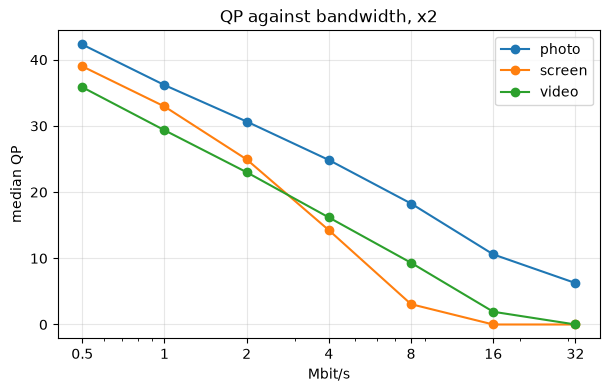

In [5]:
print(f"x{SCORED_SCALE}, by content and Mbit/s")
print(at_x2.pivot_table(index="content", columns="mbps", values="qp", aggfunc="median").round(0).to_string())

print(f"\nx{SCORED_SCALE}, by group and Mbit/s")
print(at_x2.pivot_table(index="group", columns="mbps", values="qp", aggfunc="median").round(0).to_string())

print("\nclips that fill 1080p, by stream size and Mbit/s")
full = coded[coded["height"] == SIZES[0][1]]
for content, part in full.groupby("content"):
    print(f"{content}\n" + part.pivot_table(index="scale", columns="mbps", values="qp", aggfunc="median").round(0).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for content, part in at_x2.groupby("content"):
    curve = part.groupby("mbps")["qp"].median()
    ax.plot(curve.index, curve.values, marker="o", label=content)
ax.set(xscale="log", xlabel="Mbit/s", ylabel="median QP", title=f"QP against bandwidth, x{SCORED_SCALE}")
ax.set_xticks(MBPS, [f"{mbps:g}" for mbps in MBPS])
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 4. What QP costs an upscale, and what the model adds

By QP bin at x2, means over frames. `damage`: SSIM-Y bicubic loses to the stream (against a clean downscale). `gain`:
SSIM-Y notebook 8's model adds over bicubic. Bins with fewer than 3 sources are left out.

                  frames  sources  bicubic  damage    gain   model
content qp_bin                                                    
photo   [0, 6)       283       30   0.8932  0.0007  0.0102  0.9034
        [6, 12)      160       30   0.9020  0.0046  0.0107  0.9127
        [12, 18)     178       30   0.8961  0.0130  0.0109  0.9070
        [18, 22)     174       30   0.8547  0.0284  0.0227  0.8774
        [22, 26)     146       29   0.8495  0.0500  0.0207  0.8702
        [26, 30)     187       30   0.8079  0.0803  0.0245  0.8324
        [30, 34)     219       30   0.7484  0.1374  0.0178  0.7662
        [34, 38)     212       30   0.6703  0.2048  0.0082  0.6785
        [38, 42)     165       29   0.6002  0.2762  0.0005  0.6007
        [42, 46)     101       27   0.5154  0.3509 -0.0028  0.5125
        [46, 52)      65       21   0.4525  0.4254 -0.0036  0.4489
screen  [0, 6)      1444       80   0.9401  0.0001  0.0390  0.9791
        [6, 12)      258       79   0.9298  0.0008  0.0451  0.

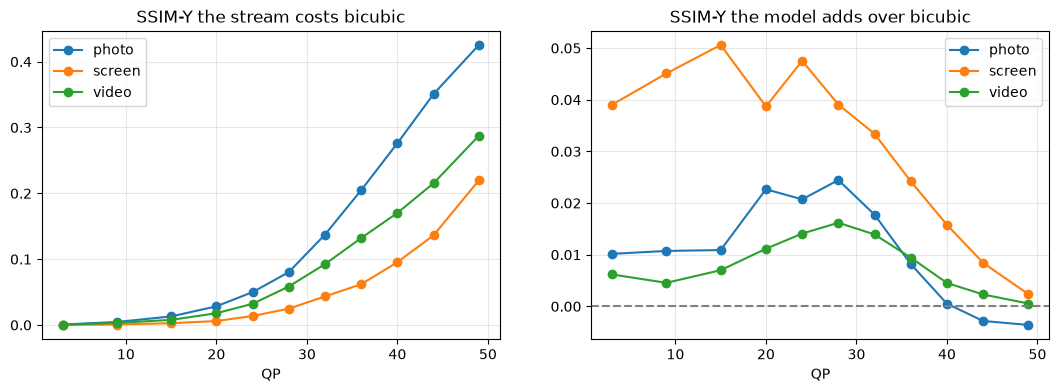

In [6]:
by_bin = scored.groupby(["content", "qp_bin"], observed=True).agg(
    frames=("qp", "size"), sources=("source", "nunique"), bicubic=("ssim bicubic", "mean"),
    damage=("damage", "mean"), gain=("gain", "mean"), model=("ssim notebook 8", "mean"))
by_bin = by_bin[by_bin["sources"] >= 3]
print(by_bin.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for content, part in by_bin.reset_index().groupby("content"):
    middle = [interval.mid for interval in part["qp_bin"]]
    axes[0].plot(middle, part["damage"], marker="o", label=content)
    axes[1].plot(middle, part["gain"], marker="o", label=content)
axes[0].set(title="SSIM-Y the stream costs bicubic", xlabel="QP")
axes[1].set(title="SSIM-Y the model adds over bicubic", xlabel="QP")
axes[1].axhline(0, color="0.5", linestyle="--")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

## 5. Pairs for notebook 18

Input: a frame of the host's stream at x2, at any QP. Target: the source frame. Targets are videos that code cheaply
(median QP under `TARGET_MAX_QP` at `REFERENCE_BPP`, x1) and have detail at their finest scale (halved and restored with
bicubic, at most `TARGET_MAX_ROUND_TRIP_DB`). Each QP bin keeps the same number of a clip's frames.

In [7]:
def round_trip_db(frames):
    """Luma PSNR of frames halved and restored with bicubic, the median: high means soft."""
    luma = torch.from_numpy(frames[SETTLE::SCORE_EVERY].astype(np.float32) @ LUMA)[:, None]
    back = F.interpolate(F.interpolate(luma, scale_factor=0.5, mode="area"), size=luma.shape[2:], mode="bicubic", align_corners=False)
    mse = ((back - luma) ** 2).mean((1, 2, 3)).clamp(min=1e-6)
    return float((10 * torch.log10(255 ** 2 / mse)).median())


def target_row(clip):
    """A video clip's median QP at `REFERENCE_BPP`, x1, and its round trip in dB."""
    frames, fps = frames_of(clip)
    if frames is None:
        return None
    (report, _), = degrade.encode_reports(frames, [degrade.Degradation(scale=1, bpp=REFERENCE_BPP, fps=fps, **PATH)])
    qp = np.median([row["qp"] for row in report if row["type"] == "P" and row["frame"] >= SETTLE])
    return {"key": clip["key"], "reference_qp": float(qp), "round_trip_db": round_trip_db(frames)}


videos = [clip for clip in clips if clip["content"] == "video"]
todo = [clip for clip in videos if clip["key"] not in done_in(TARGETS_FILE)]
print(f"targets: {len(todo)} video clips to measure")
with ThreadPoolExecutor(WORKERS) as pool:
    for row in pool.map(target_row, todo):
        append(TARGETS_FILE, [row] if row else [])

measured = pd.read_csv(TARGETS_FILE)
chosen = measured[(measured["reference_qp"] < TARGET_MAX_QP) & (measured["round_trip_db"] <= TARGET_MAX_ROUND_TRIP_DB)]
targets = [clip for clip in videos if clip["key"] in set(chosen["key"])]
print(f"{len(targets)} targets of {len(measured)} video clips: {sum(not c['scored'] for c in targets)} train, {sum(c['scored'] for c in targets)} validation")

targets: 1109 video clips to measure
394 targets of 1023 video clips: 306 train, 88 validation


In [8]:
PATCH_LR = PATCH_HR // PAIR_SCALE
INPUT_LR = PATCH_LR + 2 * HALO
QP_BINS = list(zip(INPUT_QP_EDGES[:-1], INPUT_QP_EDGES[1:]))


def lr_psnr(lr_core, hr_patch):
    """Luma PSNR of a stream spot against a clean downscale of its target."""
    clean = (hr_patch.astype(np.float32) @ LUMA).reshape(PATCH_LR, PAIR_SCALE, PATCH_LR, PAIR_SCALE).mean(axis=(1, 3))
    mse = ((lr_core.astype(np.float32) @ LUMA - clean) ** 2).mean()
    return 10 * np.log10(255 ** 2 / max(mse, 1e-10))


def spots(hr, lr, rng):
    """Up to `PATCHES_PER_FRAME` (LR with its halo, HR) of one frame, not flat and not destroyed."""
    out = []
    for _ in range(4 * PATCHES_PER_FRAME):
        if len(out) == PATCHES_PER_FRAME:
            break
        y, x = (2 * int(rng.integers(0, (size - INPUT_LR) // 2 + 1)) for size in lr.shape[:2])   # even pixels: 4:2:0
        y_hr, x_hr = (y + HALO) * PAIR_SCALE, (x + HALO) * PAIR_SCALE
        hr_patch, lr_patch = hr[y_hr:y_hr + PATCH_HR, x_hr:x_hr + PATCH_HR], lr[y:y + INPUT_LR, x:x + INPUT_LR]
        if (hr_patch.astype(np.float32) @ LUMA).var() >= VAR_MIN and lr_psnr(lr_patch[HALO:-HALO, HALO:-HALO], hr_patch) >= MIN_LR_PSNR:
            out.append((lr_patch.copy(), hr_patch.copy()))
    return out


def pairs_of(clip):
    """One target clip's patches {"lr", "hr", "qp", "sources"}: `FRAMES_PER_BIN` frames of each QP bin, found in
    whichever stream of `PAIR_MBPS` gave them, and a manifest source per stream that gave any."""
    rng = np.random.default_rng(zlib.crc32(clip["key"].encode()))
    frames, fps = frames_of(clip)
    streams, found = {}, {qp_bin: [] for qp_bin in QP_BINS}
    for mbps in PAIR_MBPS:
        made, _ = stream(mbps, frames, PAIR_SCALE, fps)
        hr, lr, _, report = degrade.degrade(frames, made, with_frames=True)
        streams[mbps] = made, lr
        for row in report:
            for low, high in QP_BINS:
                if row["type"] == "P" and row["frame"] >= SETTLE and low <= row["qp"] < high:
                    found[low, high].append((mbps, row["frame"], row["qp"]))
    chosen = {}
    for candidates in found.values():
        for i in rng.permutation(len(candidates))[:FRAMES_PER_BIN]:
            mbps, t, qp = candidates[i]
            chosen.setdefault(mbps, []).append((t, qp))
    out = {"lr": [], "hr": [], "qp": [], "sources": []}
    for mbps, picked in sorted(chosen.items()):
        made, lr = streams[mbps]
        first = len(out["lr"])
        for t, qp in picked:
            for lr_patch, hr_patch in spots(hr[t], lr[t], rng):
                out["lr"].append(lr_patch)
                out["hr"].append(hr_patch)
                out["qp"].append(qp)
        if len(out["lr"]) > first:
            out["sources"].append({"key": clip["key"], "group": clip["group"], "mbps": mbps,
                                   "patches": [first, len(out["lr"])], "degradation": made.as_dict()})
    return out


buckets = {split: {"lr": [], "hr": [], "qp": [], "sources": []} for split in ("train", "val")}
with ThreadPoolExecutor(WORKERS) as pool:
    for clip, made in zip(targets, pool.map(pairs_of, targets)):
        bucket = buckets["val" if clip["scored"] else "train"]
        offset = len(bucket["lr"])
        bucket["sources"] += [{**source, "patches": [source["patches"][0] + offset, source["patches"][1] + offset]} for source in made["sources"]]
        for name in ("lr", "hr", "qp"):
            bucket[name] += made[name]

PAIRS_DIR.mkdir(parents=True, exist_ok=True)
splits = {}
for split, bucket in buckets.items():
    np.save(PAIRS_DIR / f"{split}_lr.npy", np.stack(bucket["lr"])[:, None])   # (patches, 1 frame, h, w, 3)
    np.save(PAIRS_DIR / f"{split}_hr.npy", np.stack(bucket["hr"])[:, None])
    np.save(PAIRS_DIR / f"{split}_qp.npy", np.array(bucket["qp"], np.float32))
    splits[split] = {"patches": len(bucket["lr"]), "lr": f"{split}_lr.npy", "hr": f"{split}_hr.npy", "qp": f"{split}_qp.npy",
                     "sources": bucket["sources"]}
    print(f"{split:<6}{len(bucket['lr']):7} patches from {len({s['key'] for s in bucket['sources']})} clips")
manifest = {"scale": PAIR_SCALE, "patch_lr": PATCH_LR, "patch_hr": PATCH_HR, "halo": HALO, "input_lr": INPUT_LR,
            "frames_per_patch": 1, "splits": splits}
(PAIRS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")

train   32589 patches from 306 clips
val      9454 patches from 88 clips


616367

Check: bicubic against the target must get worse as QP rises, or the QP labels mean nothing.

In [9]:
manifest = json.loads((PAIRS_DIR / "manifest.json").read_text(encoding="utf-8"))
val_lr, val_hr = patches.load(PAIRS_DIR, "val", manifest)
val_qp = np.load(PAIRS_DIR / "val_qp.npy")
print(f"{'QP':>7}{'patches':>9}{'SSIM-Y':>9}")
with torch.no_grad():
    for low, high in QP_BINS:
        members = np.flatnonzero((val_qp >= low) & (val_qp < high))
        ssim = [metrics.per_image(patches.trim(models.bicubic(to_tensor(val_lr[batch]), PAIR_SCALE), HALO * PAIR_SCALE),
                                  to_tensor(val_hr[batch]))["ssim"].cpu() for batch in np.array_split(members, max(1, len(members) // 256))]
        print(f"{f'{low}-{high}':>7}{len(members):9}{torch.cat(ssim).mean():9.4f}")

     QP  patches   SSIM-Y
   0-18     1408   0.9568
  18-26     1408   0.9378
  26-30     1406   0.9096
  30-34     1407   0.8829
  34-38     1390   0.8434
  38-42     1347   0.8154
  42-46     1088   0.7999
